# 02 - Data Preprocessing & Exploratory Data Analysis (EDA)

**Objective:** clean the data, encode categorical variables, select and
scale the features used for clustering, and explore the dataset visually
to understand distributions, relationships, and potential outliers before
modeling.


In [5]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find project root by searching for the src directory
def find_project_root():
    """Find the project root by looking for the src directory"""
    current = os.getcwd()
    # Try current directory first
    if os.path.isdir(os.path.join(current, 'src')):
        return current
    # Try parent directory
    parent = os.path.dirname(current)
    if os.path.isdir(os.path.join(parent, 'src')):
        return parent
    # Try going up more levels
    for _ in range(5):
        parent = os.path.dirname(parent)
        if os.path.isdir(os.path.join(parent, 'src')):
            return parent
    raise RuntimeError(f"Could not find project root with src/ directory from {current}")

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Import preprocessing components
from src.preprocessing import (
    load_raw_data, clean_data, encode_categorical,
    select_features, scale_features, CLUSTERING_FEATURES, PROCESSED_DATA_PATH
)
from src.visualization import (
    plot_distribution, plot_boxplot, plot_correlation_heatmap, plot_scatter
)

print(f"✓ Project root: {PROJECT_ROOT}")
print(f"✓ Processing data path: {PROCESSED_DATA_PATH}")

✓ Project root: c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml
✓ Processing data path: c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\mall_customers_processed.csv


## 1. Load and clean data

In [6]:
raw_df = load_raw_data()
df = clean_data(raw_df)
print(f"Rows after cleaning: {len(df)}")
df.head()


Rows after cleaning: 200


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Encode categorical variable (Gender)

Gender is encoded numerically (Female=0, Male=1) for reference and for
EDA comparisons. As explained in `src/preprocessing.py`, Gender is **not**
included as a clustering feature in the main pipeline, to avoid distorting
Euclidean-distance-based clustering with an unscaled binary variable.


In [7]:
df = encode_categorical(df)
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


## 3. Feature selection

Features selected for clustering: **Age, Annual Income (k$), Spending Score (1-100)**.

These three numeric features were chosen because they directly describe
*who the customer is* and *how they behave*, which is exactly what a
retail business needs to design targeted marketing campaigns.


In [8]:
X = select_features(df, CLUSTERING_FEATURES)
print(f"Clustering feature matrix shape: {X.shape}")
X.describe().round(2)


Clustering feature matrix shape: (200, 3)


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


## 4. Feature scaling

K-Means and DBSCAN both rely on **Euclidean distance**, so features must be
on comparable scales. `Annual Income (k$)` ranges up to 137, while
`Spending Score` ranges 1-100 and `Age` ranges roughly 18-70 - without
scaling, income would dominate the distance calculation. We use
`StandardScaler` (zero mean, unit variance).


In [9]:
X_scaled, scaler = scale_features(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=CLUSTERING_FEATURES)
print("Scaled feature statistics (should be ~mean 0, ~std 1):")
X_scaled_df.describe().round(2)


Scaled feature statistics (should be ~mean 0, ~std 1):


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-1.74,-1.91
25%,-0.72,-0.73,-0.60
50%,-0.20,0.04,-0.01
75%,0.73,0.67,0.89
max,2.24,2.92,1.89


In [10]:
# Save processed dataset and scaled features for reuse in later notebooks
# Use absolute paths to ensure files are found regardless of working directory
X_SCALED_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'X_scaled.npy')

# Create directory if it doesn't exist
os.makedirs(os.path.dirname(X_SCALED_PATH), exist_ok=True)

# Save files
df.to_csv(PROCESSED_DATA_PATH, index=False)
np.save(X_SCALED_PATH, X_scaled)

print(f"✓ Processed data saved to: {PROCESSED_DATA_PATH}")
print(f"✓ Scaled features saved to: {X_SCALED_PATH}")
print(f"  Files are ready for notebooks 03 and 04")

✓ Processed data saved to: c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\mall_customers_processed.csv
✓ Scaled features saved to: c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\X_scaled.npy
  Files are ready for notebooks 03 and 04


## 5. Exploratory Data Analysis (EDA)

Every plot below is chosen to answer a specific question about the data -
we deliberately avoid generating dozens of uninformative charts.


### 5.1 Age distribution
*Question: what is the age range of mall customers?*

In [11]:
plot_distribution(df, 'Age', 'eda_age_distribution.png')


Saved figure -> results/figures\eda_age_distribution.png


<Figure size 600x400 with 1 Axes>

### 5.2 Annual Income distribution
*Question: what income levels are represented in this customer base?*

Saved figure -> results/figures\eda_income_distribution.png


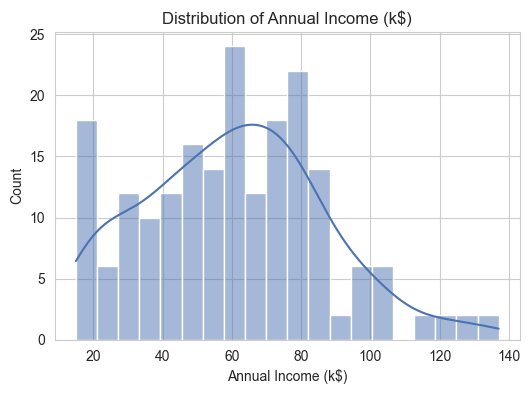

In [12]:
plot_distribution(df, 'Annual Income (k$)', 'eda_income_distribution.png')


### 5.3 Spending Score distribution
*Question: how does customer spending behavior vary?*

Saved figure -> results/figures\eda_spending_distribution.png


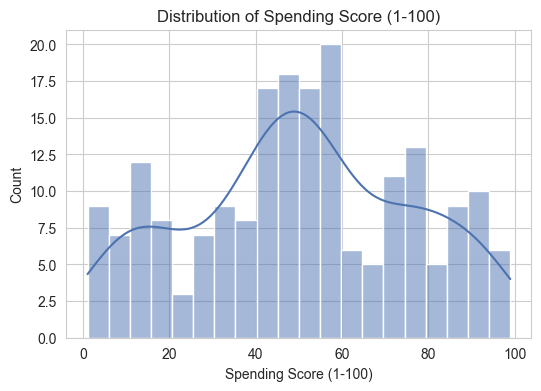

In [13]:
plot_distribution(df, 'Spending Score (1-100)', 'eda_spending_distribution.png')


### 5.4 Gender distribution
*Question: is the dataset balanced by gender?*

C:\Users\suriv\AppData\Local\Temp\ipykernel_12620\1959716869.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', ax=ax, palette='pastel')


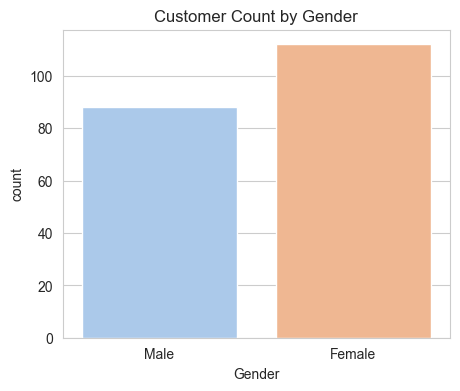

Gender
Female    112
Male       88
Name: count, dtype: int64


In [14]:
fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(data=df, x='Gender', ax=ax, palette='pastel')
ax.set_title('Customer Count by Gender')
os.makedirs('results/figures', exist_ok=True)
fig.savefig('results/figures/eda_gender_count.png', dpi=150, bbox_inches='tight')
plt.show()
print(df['Gender'].value_counts())


### 5.5 Outlier check via boxplots
*Question: do Age, Income or Spending Score contain extreme outliers?*

Saved figure -> results/figures\eda_boxplot_age.png


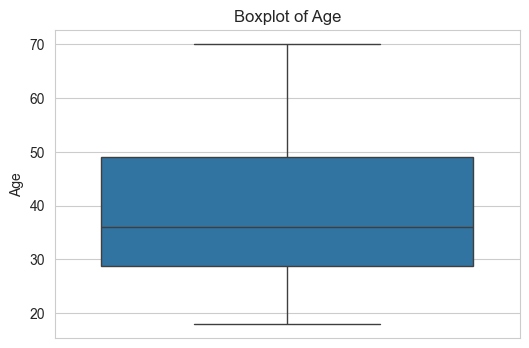

Saved figure -> results/figures\eda_boxplot_income.png


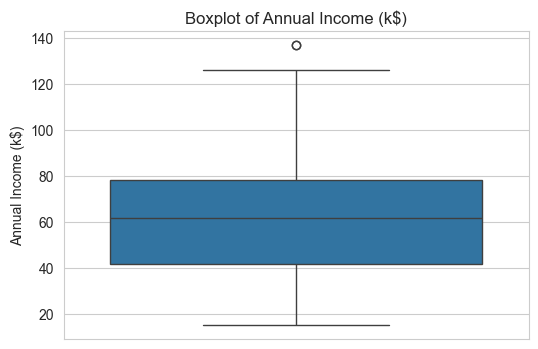

Saved figure -> results/figures\eda_boxplot_spending.png


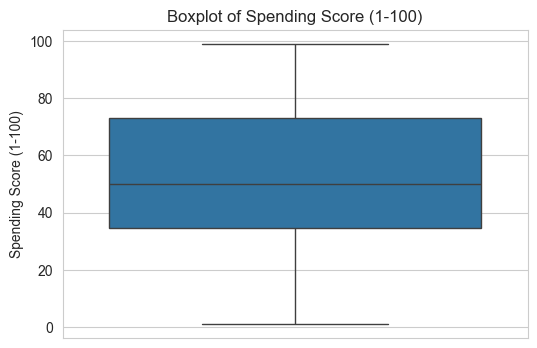

In [15]:
plot_boxplot(df, 'Age', 'eda_boxplot_age.png')
plot_boxplot(df, 'Annual Income (k$)', 'eda_boxplot_income.png')
plot_boxplot(df, 'Spending Score (1-100)', 'eda_boxplot_spending.png')


In [16]:
from scipy import stats
# Simple IQR-based outlier count for reporting purposes
def iqr_outlier_count(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    return int(((series < lower) | (series > upper)).sum())

for col in CLUSTERING_FEATURES:
    print(f"{col}: {iqr_outlier_count(df[col])} IQR outliers")


Age: 0 IQR outliers
Annual Income (k$): 2 IQR outliers
Spending Score (1-100): 0 IQR outliers


**Interpretation:** boxplots show a small number of mild outliers in
`Annual Income (k$)` (a few higher-income customers), which is expected and
realistic for income data - not a data quality problem. These points are
revisited later as a natural test case for DBSCAN's noise detection.


### 5.6 Correlation between numeric features
*Question: are Age, Income and Spending Score linearly related?*

Saved figure -> results/figures\eda_correlation_heatmap.png


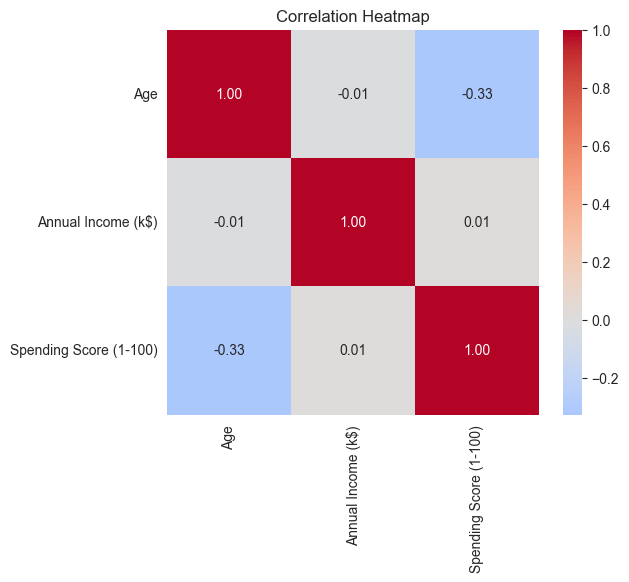

In [17]:
plot_correlation_heatmap(df, CLUSTERING_FEATURES, 'eda_correlation_heatmap.png')


**Interpretation:** correlations between Age, Income and Spending Score
are weak, meaning no single feature can substitute for the others - each
contributes distinct information, which supports using all three together
for clustering (or the two-feature Income vs Spending Score view for
visualization, as used widely in retail segmentation).


### 5.7 Annual Income vs Spending Score
*Question: is there visible group structure between these two behavioral features?*
This is the key relationship the clustering models will exploit.

c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\src\visualization.py:61: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=df, x=x, y=y, hue=hue, palette="tab10", ax=ax, s=60, edgecolor="black")


Saved figure -> results/figures\eda_income_vs_spending.png


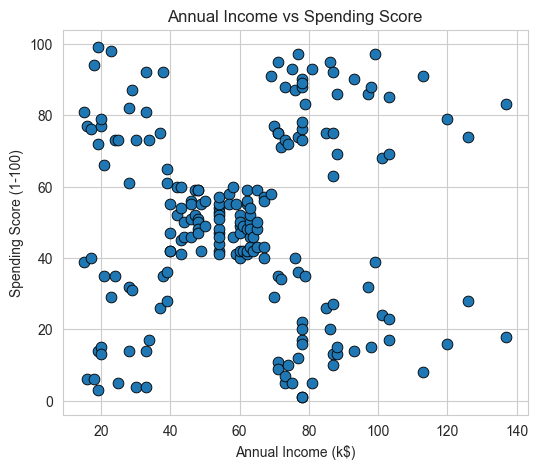

In [18]:
plot_scatter(df, 'Annual Income (k$)', 'Spending Score (1-100)',
             'eda_income_vs_spending.png',
             title='Annual Income vs Spending Score')


**Interpretation:** even before running any clustering algorithm, the
scatter plot shows visually distinct groupings (e.g. high income/high
spending, high income/low spending, low income/high spending, etc.) -
strong evidence that clustering is meaningful for this dataset.


### 5.8 Age vs Spending Score, colored by Gender
*Question: does spending behavior vary with age, and does gender play a role?*

Saved figure -> results/figures\eda_age_vs_spending_gender.png


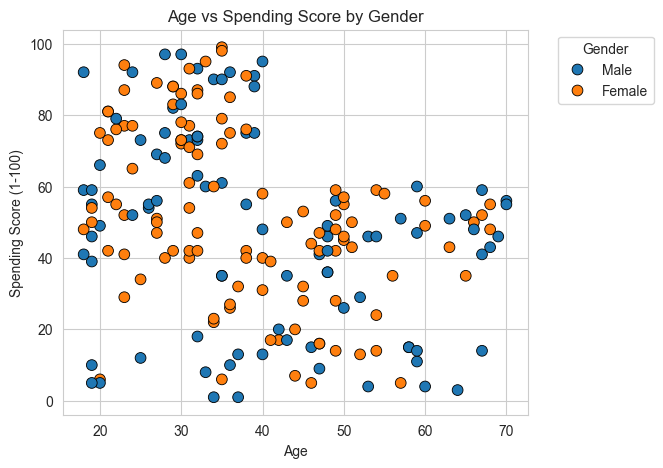

In [19]:
plot_scatter(df, 'Age', 'Spending Score (1-100)', 'eda_age_vs_spending_gender.png',
             hue='Gender', title='Age vs Spending Score by Gender')


**Interpretation:** younger customers tend to show a wider spread of
spending scores (including many high spenders), while older customers
cluster more toward moderate spending. Gender does not show a strong
visually separable effect, which is why it is excluded as a clustering
feature (kept only for descriptive EDA).


## 6. EDA Summary

- No missing values or duplicates - dataset is clean.
- Mild income outliers exist but are realistic, not data errors.
- Weak correlation between Age, Income and Spending Score -> all three
  carry unique information.
- Clear visual grouping exists in the Income vs Spending Score plot,
  which strongly motivates using clustering to formalize these groups.

Next notebook: **03_kmeans_clustering.ipynb**
